# PA2 Task 2 - Proximal Policy Optimization (Kaggle, also runs on Colab)

**The setup.** PPO is *online*: every update, the policy writes an answer, a frozen reward model scores
it, a critic (Qwen2.5-0.5B + value head) estimates how good each moment was, and the policy is nudged
towards better-than-expected tokens. Clipping (epsilon) limits how far one batch can move the policy;
the KL penalty (beta_KL) limits how far it drifts from the reference overall. Every run here starts
from the **same supplied midpoint** checkpoint.

| Run | Updates | epsilon | beta_KL | What it is for |
|---|---|---|---|---|
| `midpoint` | 0 | - | - | evaluation only: the starting point every run is compared with |
| `standard` | 20 | 0.20 | 0.10 | required continuation (Task 4 reuses this adapter) |
| `fork_eps0.05_kl0.1`, `fork_eps0.5_kl0.1` | 8 | 0.05 / 0.50 | 0.10 | clipping study |
| `fork_eps0.2_kl0.1` | 8 | 0.20 | 0.10 | **shared** by both studies (trained once) |
| `fork_eps0.2_kl0`, `fork_eps0.2_kl0.2` | 8 | 0.20 | 0 / 0.20 | KL-pressure study |
| cached batch | 0 | all three | 0.10 | clipping geometry on the supplied rollouts, no generation |
| `smoke` | 2 | 0.20 | 0.10 | pipeline test only, **never reported** |

**Four rules this notebook enforces**
1. **The bug fix is proven before any training.** T5 tests the four clipping cases (values AND which
   ones get a gradient) and the GAE arithmetic by hand, and stops the notebook on any mismatch.
2. **Every fork is matched.** Same midpoint, same prompt schedule, same per-update sampling seed, same
   update budget; T10/T11 check this from the saved logs and report generated tokens per fork.
3. **One held-out protocol.** Same prompts, decoding, seed and 768-token cap for every condition.
4. **Task 4 uses `standard` only**, never a fork, whatever the forks show.

**Inputs (Kaggle)**
- Settings -> **Accelerator: GPU T4 x2**, **Internet: ON**.
- **Add Input -> dataset `pa2-task2`**: upload `pa2-task2.zip` (the fixed `task2_ppo/` files).
- *(Resuming only)* add the **output of a previous version** of this notebook; finished runs are skipped.

**Timing on a T4 (rough; T7 prints a real estimate):** setup and checks 25 min; each update about
30-60 s (one 512-token rollout + 2 passes), so standard 15-20 min and the 5 forks 25-40 min; each
held-out evaluation 10-20 min x 7 conditions; cached analysis 5-15 min. About 3-5 h in total.
Use **Save Version -> Save & Run All (Commit)**.

**How to read the output.** `PASS / FAIL / OBSERVE`, then the **expected** and **actual** lines.
`OBSERVE` = a finding for your report; the expected line states the hypothesis being tested.

## Part A - setup

In [1]:
# T1. Assemble the repo, connect the saved output folder, and layer in the fixed Task 2 files.
import os, sys, glob, json, math, shutil, subprocess, time, zipfile
from pathlib import Path

ON_KAGGLE = os.path.exists('/kaggle/working')
REPO_URL  = 'https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git'   # <- or YOUR repo with the fixed task2_ppo/
REPO      = '/tmp/PA2'
N_EVAL    = 100          # held-out prompts per condition (capped at the pool size in T4); identical for all
SMOKE_UPD = 2
RUN_PARTS = {'C_standard': True, 'D_clip': True, 'E_kl': True}

if ON_KAGGLE:
    OUT, BASE = '/kaggle/working/outputs', '/kaggle/input'
    os.environ['HF_HOME'] = '/tmp/hf'
else:
    from google.colab import drive; drive.mount('/content/drive')
    OUT  = '/content/drive/MyDrive/ATML_PA2/task2_outputs'
    BASE = '/content/drive/MyDrive/ATML_PA2/inputs'
    os.environ['HF_HOME'] = '/content/hf'
for sub in ['outputs', 'results']:
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)

CHECKS = []
def expect(name, expected, actual, ok):
    ok = None if ok is None else bool(ok)
    tag = {True: 'PASS   ', False: 'FAIL   ', None: 'OBSERVE'}[ok]
    print(f'[{tag}] {name}\n            expected: {expected}\n            actual  : {actual}')
    CHECKS.append((tag.strip(), name))

def run(cmd):
    print('$', cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='')
    if p.wait() != 0:
        raise RuntimeError(f'Command failed (exit code {p.returncode}): {cmd}')

if not os.path.isdir(f'{REPO}/.git'):
    subprocess.run(f'git clone -q {REPO_URL} {REPO}', shell=True, check=True)
os.chdir(REPO); sys.path.insert(0, REPO)
print('  cloned      :', REPO_URL)

FILES = ['ppo.py', 'continue_train.py', 'evaluate.py', 'analyze_clipping.py', 'ablate_kl.py']
FIX_MARK = 'objective = torch.minimum(surr1, surr2)'
hits = [p for p in glob.glob(f'{BASE}/**/ppo.py', recursive=True) if FIX_MARK in open(p).read()]
if hits:
    src_dir = os.path.dirname(hits[0])
    for f in FILES:
        shutil.copy(f'{src_dir}/{f}', f'{REPO}/task2_ppo/{f}')
    print('  layered in  :', src_dir)
else:
    print('  layered in  : nothing found under', BASE)

for sub in ['outputs', 'results']:
    local = Path(REPO, sub)
    if local.is_symlink():
        continue
    if local.exists():
        shutil.copytree(local, f'{OUT}/{sub}', dirs_exist_ok=True); shutil.rmtree(local)
    local.symlink_to(f'{OUT}/{sub}', target_is_directory=True)

if ON_KAGGLE:
    for kind in ['outputs', 'results']:
        for prev in glob.glob(f'{BASE}/**/{kind}/task2_ppo', recursive=True):
            shutil.copytree(prev, f'{OUT}/{kind}/task2_ppo', dirs_exist_ok=True)
            print(f'  resumed     : {prev}')

src = {f: open(f'task2_ppo/{f}').read() for f in FILES}
expect('ppo.py carries the bug fix', f'the line `{FIX_MARK}` (starter: torch.maximum)', 'found' if FIX_MARK in src['ppo.py'] else 'NOT found', FIX_MARK in src['ppo.py'])
expect('training / evaluation / studies are implemented', 'no NotImplementedError left',
       [f for f in FILES[1:] if 'NotImplementedError' in src[f]] or 'none left', not any('NotImplementedError' in src[f] for f in FILES[1:]))
done = sorted(p.parent.name for p in Path(f'{OUT}/outputs/task2_ppo').glob('*/adapter_config.json'))
print(f'\n  repo    : {REPO}\n  outputs : {OUT}\n  adapters already trained (will be skipped): {done or "none"}')
assert FIX_MARK in src['ppo.py'], 'Attach the pa2-task2 dataset (or set REPO_URL to your repo) before continuing.' 

  cloned      : https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git
  layered in  : /kaggle/input/datasets/zylah628/pa2-task2/pa2-task2 (1)
[PASS   ] ppo.py carries the bug fix
            expected: the line `objective = torch.minimum(surr1, surr2)` (starter: torch.maximum)
            actual  : found
[PASS   ] training / evaluation / studies are implemented
            expected: no NotImplementedError left
            actual  : none left

  repo    : /tmp/PA2
  outputs : /kaggle/working/outputs
  adapters already trained (will be skipped): none


In [2]:
# T2. Install the pinned environment and fetch the fixed course assets (Internet must be ON).
run('pip install -q -r requirements.txt')
run('python -m scripts.download_assets')
run('python -m scripts.validate_assets')
run('python -m scripts.check_environment')
expect('course assets', 'download_assets + validate_assets exit 0', 'both exited 0', True)

$ pip install -q -r requirements.txt
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 93.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.9/530.9 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
$ p

In [3]:
# T3. Helpers. report_ppo() prints a health summary of one run, saves its curves, returns a verdict.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

RES = 'results/task2_ppo'; FIG = f'{RES}/figures'; os.makedirs(FIG, exist_ok=True)
def read_jsonl(p): return [json.loads(l) for l in open(p) if l.strip()]
def load_json(p):  return json.load(open(p))
def clip(s, n=300):
    s = ' '.join(str(s).split()); return s if len(s) <= n else s[:n] + ' ...'
def has_adapter(n): return os.path.exists(f'outputs/task2_ppo/{n}/adapter_config.json')
def has_eval(n):    return os.path.exists(f'{RES}/{n}/eval_metrics.json')
def q(rows, k):     return float(np.mean([r[k] for r in rows]))

def report_ppo(run_name, plot=True):
    """What to look for:
       pass-0 |rho-1|   must be ~0: before the first step pi_new == pi_old exactly (dropout off)
       reward / KL      single-sample per update -> noisy; read the first-vs-last-quarter means
       entropy          a steady fall = the policy is getting more certain / repetitive
       value loss, EV   is the critic tracking the returns? EV near 1 good, near 0 or < 0 poor
       clip fraction    on the LAST pass (pass 0 is 0 by construction)
       approx KL        how far a single update moved the policy; > 0.05 is a large step
       skipped steps    fp16 overflow -> GradScaler skips that step; a few are normal"""
    d = f'{RES}/{run_name}'
    log, s = read_jsonl(f'{d}/train_log.jsonl'), load_json(f'{d}/train_summary.json')
    k = max(1, len(log) // 4); a, b = log[:k], log[-k:]
    p0 = max(r['passes'][0]['max_abs_ratio_minus_1'] for r in log)
    gn = [r['grad_norm'] for r in log]; bad_gn = sum(not math.isfinite(x) for x in gn)
    ev = [r['explained_variance'] for r in log if r['explained_variance'] == r['explained_variance']]
    print(f'\n=== {run_name} ===  (eps = {s["eps"]}, beta_KL = {s["beta_kl"]}, {s["updates"]} updates x {s["prompts_per_update"]} prompt, {s["ppo_epochs"]} passes)')
    print(f'  wall clock / peak VRAM  : {s["wall_clock_s"]/60:.1f} min, {s["peak_vram_gb"]:.2f} GB, {s["generated_tokens"]} generated tokens  [{s["precision"]}]')
    print(f'  reward (first -> last quarter)   : {q(a,"reward"):+.3f} -> {q(b,"reward"):+.3f}   (penalized {q(a,"reward_penalized"):+.3f} -> {q(b,"reward_penalized"):+.3f})')
    print(f'  KL from reference (token mean)   : {q(a,"kl_ref"):.4f} -> {q(b,"kl_ref"):.4f}')
    print(f'  entropy (sampled helper)         : {q(a,"entropy"):.3f} -> {q(b,"entropy"):.3f}')
    print(f'  response length / truncated      : {q(a,"response_length"):.0f} -> {q(b,"response_length"):.0f} tokens; cut off on {sum(r["truncated"] > 0 for r in log)}/{len(log)} updates')
    print(f'  value loss                       : {q(a,"value_loss"):.3f} -> {q(b,"value_loss"):.3f};  explained variance median {np.median(ev) if ev else float("nan"):+.2f} (1 = perfect critic)')
    print(f'  clip fraction (last pass)        : mean {q(log,"clip_fraction_last"):.4f}, max {max(r["clip_fraction_last"] for r in log):.4f}; affected (grad zeroed) mean {q(log,"active_clip_fraction_last"):.4f}')
    print(f'  approx KL(old||new) per update   : median {np.median([r["approx_kl_old_new"] for r in log]):.2e}, max {max(r["approx_kl_old_new"] for r in log):.2e}')
    print(f'  policy grad norm (pre-clip)      : median {np.nanmedian(gn):.3f}, max {np.nanmax(gn):.3f}; non-finite (skipped) on {bad_gn}/{len(gn)}')
    print(f'  pass-0 max |rho - 1|             : {p0:.2e}  (must be ~0)')
    lossbad = any(not math.isfinite(r['policy_loss']) or not math.isfinite(r['value_loss']) for r in log)
    v = ('BROKEN (non-finite loss)' if lossbad else
         'CHECK (pass-0 ratio != 1: dropout on, or old/new log-prob mismatch)' if p0 > 1e-2 else
         'CHECK (more than 10% of steps skipped by the GradScaler)' if bad_gn > 0.1 * len(gn) else
         'LARGE STEPS (an update moved KL(old||new) > 0.05)' if max(r['approx_kl_old_new'] for r in log) > 0.05 else 'STABLE')
    print(f'  VERDICT: {v}')
    if 0 < bad_gn <= 0.1 * len(gn):
        print(f'  note: {bad_gn} skipped step(s) = normal fp16 behaviour (GradScaler halves its scale and skips one update).')
    if plot:
        u = [r['update'] for r in log]
        panels = [('reward', 'reward (single rollout)'), ('kl_ref', 'KL from reference'), ('entropy', 'entropy'),
                  ('response_length', 'response length'), ('policy_loss', 'policy loss'), ('value_loss', 'value loss'),
                  ('clip_fraction_last', 'clip fraction (last pass)'), ('grad_norm', 'policy grad norm')]
        fig, axes = plt.subplots(2, 4, figsize=(17, 5.5))
        for ax, (key, title) in zip(axes.flat, panels):
            y = pd.Series([r[key] for r in log], dtype=float)
            ax.plot(u, y, '.', alpha=.45); ax.plot(u, y.rolling(max(2, len(log) // 5), min_periods=1).mean())
            ax.set_title(f'{run_name}: {title}', fontsize=8); ax.set_xlabel('update'); ax.grid(alpha=.3)
        fig.tight_layout(); fig.savefig(f'{FIG}/curves_{run_name}.png', dpi=140); plt.show(); plt.close(fig)
    return v, s, log

def eval_row(name):
    m = load_json(f'{RES}/{name}/eval_metrics.json')
    return {'condition': name, 'reward': m['reward_mean'], 'reward_std': m['reward_std'], 'reward_penalized': m['reward_penalized_mean'],
            'kl_token': m['kl_token_mean'], 'kl_seq': m['kl_seq_mean'], 'entropy': m['entropy_sampled'], 'entropy_exact': m['entropy_exact'],
            'len_mean': m['length_tokens']['mean'], 'len_std': m['length_tokens']['std'], 'len_iqr': m['length_tokens']['iqr'],
            'trunc_rate': m['truncation_rate'], 'distinct2': m['distinct2_mean'], 'n_prompts': m['n_prompts']}
print('Helpers ready.  results ->', os.path.realpath(RES))

Helpers ready.  results -> /kaggle/working/outputs/results/task2_ppo


In [4]:
# T4. GPU, config, data and cache check -- before any GPU time is spent.
import torch
from common.data import load_yaml, prompt_messages, read_jsonl as rj
cfg = load_yaml('configs/ppo.yaml')
gpu = torch.cuda.is_available()
expect('GPU present', 'a CUDA GPU (T4)', torch.cuda.get_device_name(0) if gpu else 'NONE', gpu); assert gpu
mem = torch.cuda.get_device_properties(0).total_memory / 1e9
expect('GPU memory', '>= 14.5 GB', f'{mem:.1f} GB', mem >= 14.5)

KEYS = ['updates', 'fork_updates', 'prompts_per_update', 'ppo_epochs', 'clip_epsilon', 'clip_values', 'kl_beta', 'kl_values',
        'policy_learning_rate', 'value_lora_learning_rate', 'value_head_learning_rate', 'value_train_mode', 'gamma', 'gae_lambda',
        'value_coef', 'missing_eos_penalty', 'max_prompt_length', 'max_response_length', 'eval_max_response_length', 'max_grad_norm']
print('  config (configs/ppo.yaml + base.yaml):')
for k in KEYS: print(f'    {k:26s} {cfg.get(k)}')
print(f'    {"generation":26s} {cfg["generation"]}   seed {cfg["seed"]}')

PT, PE = rj(cfg['paths']['rl_prompt_train']), rj(cfg['paths']['rl_prompt_eval'])
N_EVAL = min(N_EVAL, len(PE))
print(f'\n  rl_prompt_train {len(PT)} rows | fields {sorted(PT[0])}')
print(f'  rl_prompt_eval  {len(PE)} rows | fields {sorted(PE[0])}  -> evaluating on the first {N_EVAL}')
print('  example prompt  :', clip(prompt_messages(PT[0])[-1]['content'], 200))
need = cfg['updates'] * cfg['prompts_per_update']
expect('enough training prompts', f'>= {need} (20 updates x {cfg["prompts_per_update"]})', len(PT), len(PT) >= need)
for k in ['ppo_midpoint_policy', 'ppo_midpoint_value']:
    p = cfg['paths'][k]; expect(f'checkpoint {k}', 'folder exists', p, os.path.isdir(p))

from task2_ppo.analyze_clipping import load_cached_rollouts, rebuild
from common.models import load_tokenizer
tok = load_tokenizer(cfg['base_model'])
cache = load_cached_rollouts(cfg['cached_rollouts'])
print(f'\n  cached rollouts : {len(cache)} | keys {sorted(cache[0])}')
R, rep = rebuild(cache, tok, {'rl_prompt_train': PT, 'rl_prompt_eval': PE}, int(cfg['max_prompt_length']))
print('  reconstruction  :', rep)
ok_align = rep['length_mismatch_cut'] == 0 and rep.get('count_mismatch', 0) == 0
expect('cache: re-tokenised responses align with the cached log-probs', '0 rows cut, 0 rows whose length differs from response_tokens (affects ONLY Part A; not a gate)',
       f'cut {rep["length_mismatch_cut"]}, count mismatches {rep.get("count_mismatch", 0)}, EOS re-added {rep["length_mismatch_fixed"]}', True if ok_align else None)
lens = [len(r['ids']) for r in R]
print(f'  cached response tokens: median {np.median(lens):.0f}, max {max(lens)}; ending with EOS: {sum(r["ends_eos"] for r in R)}/{len(R)}')
print(f'  cached terminal reward: {R[0]["cached_reward"] is not None} (penalty already included: {R[0]["reward_includes_penalty"]}); cached critic values: {R[0]["cached_values"] is not None}')

[PASS   ] GPU present
            expected: a CUDA GPU (T4)
            actual  : Tesla T4
[PASS   ] GPU memory
            expected: >= 14.5 GB
            actual  : 15.6 GB
  config (configs/ppo.yaml + base.yaml):
    updates                    20
    fork_updates               8
    prompts_per_update         1
    ppo_epochs                 2
    clip_epsilon               0.2
    clip_values                [0.05, 0.2, 0.5]
    kl_beta                    0.1
    kl_values                  [0.0, 0.1, 0.2]
    policy_learning_rate       3e-06
    value_lora_learning_rate   0.0001
    value_head_learning_rate   0.0003
    value_train_mode           lora_head
    gamma                      1.0
    gae_lambda                 0.95
    value_coef                 0.5
    missing_eos_penalty        1.0
    max_prompt_length          256
    max_response_length        512
    eval_max_response_length   768
    max_grad_norm              1.0
    generation                 {'temperature': 0.7,

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


  cached rollouts : 32 | keys ['clipped_at_max', 'effective_terminal_reward', 'old_logprobs', 'prompt_id', 'raw_terminal_reward', 'ref_logprobs', 'response', 'response_tokens', 'source_index', 'terminated_with_eos', 'values']
  reconstruction  : {'prompt_source': {'rl_prompt_eval by prompt_id': 32}, 'ids_from': {'re-tokenised text': 32}, 'length_mismatch_fixed': 24, 'length_mismatch_cut': 0}
[PASS   ] cache: re-tokenised responses align with the cached log-probs
            expected: 0 rows cut, 0 rows whose length differs from response_tokens (affects ONLY Part A; not a gate)
            actual  : cut 0, count mismatches 0, EOS re-added 24
  cached response tokens: median 292, max 512; ending with EOS: 24/32
  cached terminal reward: True (penalty already included: True); cached critic values: True


## Part B - prove the pipeline before spending GPU hours

T5 checks the maths by hand on CPU; T6 runs one real rollout and two passes; T7 runs the real script for 2 updates and tests the evaluator. Each FAIL here is cheap to fix now.

In [5]:
# T5. Unit tests on CPU, against hand calculations. The notebook STOPS here on any mismatch.
from task2_ppo.ppo import (ppo_policy_loss, active_clip_fraction, compute_gae, shaped_rewards,
                           normalize_advantages, explained_variance)
eps = 0.2
cases = [('1: A=+1, rho=1.5', 1.0, 1.5,  1.2, False), ('2: A=+1, rho=0.7', 1.0, 0.7,  0.7, True),
         ('3: A=-1, rho=0.7', -1.0, 0.7, -0.8, False), ('4: A=-1, rho=1.5', -1.0, 1.5, -1.5, True)]
starter = {'1': 1.5, '2': 0.8, '3': -0.7, '4': -1.2}
print('The four clipping cases (eps = 0.2). Objective = min(rho*A, clip(rho)*A); gradient = d objective / d log pi_new')
for name, A, rho, want, grad_flows in cases:
    new = torch.tensor([math.log(rho)], requires_grad=True); old = torch.zeros(1)
    loss, _, _ = ppo_policy_loss(new, old, torch.tensor([A]), torch.ones(1), eps)
    (-loss).backward(); g = float(new.grad)
    expect(f'case {name}', f'objective {want:+.1f}, gradient {"flows" if grad_flows else "zero"}   (starter max would give {starter[name[0]]:+.1f})',
           f'objective {-float(loss):+.2f}, gradient {g:+.2f}', abs(-float(loss) - want) < 1e-6 and ((abs(g) > 1e-6) == grad_flows))
r4 = torch.tensor([1.5, 0.7, 0.7, 1.5]); A4 = torch.tensor([1.0, 1.0, -1.0, -1.0])
_, _, cf = ppo_policy_loss(torch.log(r4), torch.zeros(4), A4, torch.ones(4), eps)
af = active_clip_fraction(r4, A4, torch.ones(4), eps)
expect('clip fraction vs affected fraction on the 4 cases', 'clip fraction 1.0 (all outside [0.8,1.2]); affected 0.5 (only cases 1 and 3 lose their gradient)', f'{float(cf):.2f} / {float(af):.2f}', float(cf) == 1.0 and float(af) == 0.5)

print('\nShaped reward + GAE, the worked example from the explanation (gamma = 1, lambda = 0.95, beta_KL = 0.1):')
lo, lr = torch.tensor([[-1.0, -0.5, -2.0]]), torch.tensor([[-1.2, -0.9, -1.8]])
rw = shaped_rewards(torch.tensor([2.0]), lo, lr, torch.ones(1, 3), 0.1)
expect('shaped rewards', '[-0.02, -0.04, +2.02]', [round(x, 4) for x in rw[0].tolist()], torch.allclose(rw, torch.tensor([[-0.02, -0.04, 2.02]]), atol=1e-6))
V = torch.tensor([[1.5, 1.6, 1.9]])
adv, ret = compute_gae(rw, V, torch.ones(1, 3), 1.0, 0.95)
expect('GAE advantages', '[0.4353, 0.374, 0.12]', [round(x, 4) for x in adv[0].tolist()], torch.allclose(adv, torch.tensor([[0.4353, 0.374, 0.12]]), atol=1e-4))
expect('returns = A + V', '[1.9353, 1.974, 2.02]', [round(x, 4) for x in ret[0].tolist()], torch.allclose(ret, torch.tensor([[1.9353, 1.974, 2.02]]), atol=1e-4))
rwp = torch.cat([rw, torch.tensor([[5.0, 5.0]])], 1); Vp = torch.cat([V, torch.tensor([[9.0, 9.0]])], 1); mp = torch.tensor([[1., 1, 1, 0, 0]])
advp, _ = compute_gae(rwp * mp, Vp * mp, mp, 1.0, 0.95)
expect('GAE ignores padding after EOS', 'same 3 advantages, then 0, 0', [round(x, 4) for x in advp[0].tolist()], torch.allclose(advp[0, :3], adv[0], atol=1e-6) and advp[0, 3:].abs().sum() == 0)
w = normalize_advantages(torch.tensor([[1.0, 2.0, 3.0, 99.0]]), torch.tensor([[1., 1, 1, 0]]))
expect('whitening over valid tokens', 'mean 0, std 1, padding stays 0', f'mean {w[0,:3].mean():+.1e}, std {w[0,:3].std(unbiased=False):.3f}, pad {w[0,3]:.1f}',
       abs(float(w[0, :3].mean())) < 1e-6 and abs(float(w[0, :3].std(unbiased=False)) - 1) < 1e-4 and float(w[0, 3]) == 0)
ret2 = torch.tensor([[1.0, 2.0, 3.0]])
expect('explained variance', 'perfect critic -> 1.0;  constant mean prediction -> 0.0',
       f'{explained_variance(ret2, ret2, torch.ones(1,3)):.2f} / {explained_variance(torch.full((1,3), 2.0), ret2, torch.ones(1,3)):.2f}',
       abs(explained_variance(ret2, ret2, torch.ones(1, 3)) - 1) < 1e-6 and abs(explained_variance(torch.full((1, 3), 2.0), ret2, torch.ones(1, 3))) < 1e-6)
assert not [n for t, n in CHECKS if t == 'FAIL'], 'A unit test failed -- stop and fix before any GPU work.' 

The four clipping cases (eps = 0.2). Objective = min(rho*A, clip(rho)*A); gradient = d objective / d log pi_new
[PASS   ] case 1: A=+1, rho=1.5
            expected: objective +1.2, gradient zero   (starter max would give +1.5)
            actual  : objective +1.20, gradient +0.00
[PASS   ] case 2: A=+1, rho=0.7
            expected: objective +0.7, gradient flows   (starter max would give +0.8)
            actual  : objective +0.70, gradient +0.70
[PASS   ] case 3: A=-1, rho=0.7
            expected: objective -0.8, gradient zero   (starter max would give -0.7)
            actual  : objective -0.80, gradient +0.00
[PASS   ] case 4: A=-1, rho=1.5
            expected: objective -1.5, gradient flows   (starter max would give -1.2)
            actual  : objective -1.50, gradient -1.50
[PASS   ] clip fraction vs affected fraction on the 4 cases
            expected: clip fraction 1.0 (all outside [0.8,1.2]); affected 0.5 (only cases 1 and 3 lose their gradient)
            actual  : 1.00 

/tmp/ipykernel_23/1478072273.py:14: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  f'objective {-float(loss):+.2f}, gradient {g:+.2f}', abs(-float(loss) - want) < 1e-6 and ((abs(g) > 1e-6) == grad_flows))


In [6]:
# T6. GPU sanity on ONE real rollout from the midpoint (in this notebook process, then freed).
#   (a) rollout, reward, critic values and advantages all have the right shapes and finite values
#   (b) pass 0: rho == 1 exactly and clip fraction 0 (nothing has changed yet; dropout is off)
#   (c) pass 1: the policy HAS moved (approx KL > 0) but only a little
from task2_ppo.continue_train import prepare_ppo_continuation, collect_rollout, ppo_pass
from common.models import clear_gpu
bundle = prepare_ppo_continuation('configs/ppo.yaml')
ro = collect_rollout(bundle, [PT[0]], float(cfg['kl_beta']), rollout_seed=int(cfg['seed']))
m = ro['mask']
print('  PROMPT  :', clip(ro['msgs'][0][-1]['content'], 160))
print('  ANSWER  :', clip(ro['responses'][0], 300))
expect('(a) rollout', f'1..{cfg["max_response_length"]} tokens; reward finite', f'{ro["lengths"][0]} tokens{" (CUT OFF -> -1.0 penalty)" if ro["truncated"][0] else ""}; reward {float(ro["raw_reward"][0]):+.3f}',
       0 < ro['lengths'][0] <= cfg['max_response_length'] and math.isfinite(float(ro['raw_reward'][0])))
expect('(a) critic values aligned with response tokens', f'shape {tuple(m.shape)} like the mask, all finite', f'{tuple(ro["values"].shape)}, finite = {bool(torch.isfinite(ro["values"]).all())}',
       ro['values'].shape == m.shape and bool(torch.isfinite(ro['values']).all()))
expect('(a) whitened advantages', 'mean ~0, std ~1 over response tokens', f'mean {float(ro["adv_w"][m.bool()].mean()):+.2e}, std {float(ro["adv_w"][m.bool()].std(unbiased=False)):.3f}',
       abs(float(ro['adv_w'][m.bool()].mean())) < 1e-3 and abs(float(ro['adv_w'][m.bool()].std(unbiased=False)) - 1) < 1e-2)
expect('(a) KL of the midpoint from the reference', '> 0 (the midpoint already drifted during staff training)', f'{ro["kl_ref"]:.4f} per token, {ro["kl_ref_seq"]:.2f} per answer', None)
expect('(a) critic quality on this rollout', 'no right answer; EV near 1 = critic tracks returns (README: the critic is deliberately imperfect)', f'EV {ro["explained_variance"]:+.3f}; mean V {float((ro["values"]*m).sum()/m.sum()):+.3f} vs mean return {float((ro["returns"]*m).sum()/m.sum()):+.3f}', None)
scalers = {k: torch.amp.GradScaler('cuda') for k in ['policy', 'value']}
p0 = ppo_pass(bundle, ro, float(cfg['clip_epsilon']), scalers)
expect('(b) pass 0: ratio', 'max |rho - 1| ~ 0 (< 1e-3) and clip fraction 0', f'{p0["max_abs_ratio_minus_1"]:.2e}, clip {p0["clip_fraction"]:.4f}', p0['max_abs_ratio_minus_1'] < 1e-3 and p0['clip_fraction'] == 0)
p1 = ppo_pass(bundle, ro, float(cfg['clip_epsilon']), scalers)
expect('(c) pass 1: the policy moved, a little', 'approx KL(old||new) > 0 and < 0.05', f'{p1["approx_kl_old_new"]:.2e}; clip fraction {p1["clip_fraction"]:.4f}; grad norm {p1["grad_norm"]:.3f}',
       0 < p1['approx_kl_old_new'] < 0.05)
expect('(c) losses finite', 'policy and value losses are numbers', f'policy {p1["policy_loss"]:+.4f}, value {p1["value_loss"]:.4f}', math.isfinite(p1['policy_loss']) and math.isfinite(p1['value_loss']))
del bundle, ro; clear_gpu()
print(f'\n  GPU memory still held by this notebook: {torch.cuda.memory_allocated() / 1e9:.2f} GB')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

  PROMPT  : best rclone mount command to mount google drive to play/stream 4k files with bit rate up to 100 Mbps for plex use new line for ever line of mount I have a 400 m ...
  ANSWER  : To use Rclone to mount Google Drive and stream 4K files at least up to 100 Mbps using Plex, you'll need to follow these steps: 1. **Install Rclone**: If you haven't already installed Rclone on your system, you can do so via pip: ```sh pip install rclone ``` 2. **Create the Mount Point**: First, crea ...
[PASS   ] (a) rollout
            expected: 1..512 tokens; reward finite
            actual  : 512 tokens (CUT OFF -> -1.0 penalty); reward +1.407
[PASS   ] (a) critic values aligned with response tokens
            expected: shape (1, 512) like the mask, all finite
            actual  : (1, 512), finite = True
[PASS   ] (a) whitened advantages
            expected: mean ~0, std ~1 over response tokens
            actual  : mean -7.45e-09, std 1.000
[OBSERVE] (a) KL of the midpoint from the reference


In [7]:
# T7. Smoke run: 2 real updates through the training SCRIPT, plus a 4-prompt evaluation of the
# evaluator itself (base Qwen must have KL exactly 0). Measures your GPU's speed for the estimate.
for d in ['outputs/task2_ppo/smoke', f'{RES}/smoke']:
    shutil.rmtree(d, ignore_errors=True)
run(f'python -m task2_ppo.continue_train --config configs/ppo.yaml --run-name smoke --updates {SMOKE_UPD} --output outputs/task2_ppo/smoke')
log, summ = read_jsonl(f'{RES}/smoke/train_log.jsonl'), load_json(f'{RES}/smoke/train_summary.json')
expect('smoke: updates logged + adapter saved', f'{SMOKE_UPD} rows, adapter_config.json', f'{len(log)} rows, adapter {has_adapter("smoke")}', len(log) == SMOKE_UPD and has_adapter('smoke'))
expect('smoke: pass-0 ratio on every update', 'max |rho - 1| < 1e-3', [f'{r["passes"][0]["max_abs_ratio_minus_1"]:.1e}' for r in log], all(r['passes'][0]['max_abs_ratio_minus_1'] < 1e-3 for r in log))
expect('smoke: losses finite', 'all finite', [(round(r['policy_loss'], 4), round(r['value_loss'], 4)) for r in log], all(math.isfinite(r['policy_loss']) and math.isfinite(r['value_loss']) for r in log))
SEC_UPD = summ['wall_clock_s'] / SMOKE_UPD
import importlib, task2_ppo.evaluate as ev; importlib.reload(ev)
t0 = time.time(); m0 = ev.evaluate_policy('configs/ppo.yaml', 'none', 'smoke_base', n_prompts=4); t_eval4 = time.time() - t0
expect('evaluator on base Qwen: KL', '0 up to float noise (the policy IS the reference)', f'{m0["kl_token_mean"]:.2e}', abs(m0['kl_token_mean']) < 1e-4)
expect('evaluator: lengths within the eval cap', f'<= {cfg["eval_max_response_length"]}', m0['length_tokens'], m0['length_tokens']['mean'] <= cfg['eval_max_response_length'])
sec_eval = (t_eval4 - 60) / 4 if t_eval4 > 120 else t_eval4 / 4      # subtract roughly 1 min of model loading
plan = [('standard: 20 updates', 20 * SEC_UPD), ('5 forks x 8 updates', 40 * SEC_UPD), ('7 evaluations', 7 * (60 + N_EVAL * sec_eval)),
        ('cached-batch analysis', 15 * 60)]
print(f'\n  speed: {SEC_UPD:.0f} s per update; ~{sec_eval:.0f} s per evaluation prompt (768-token cap)')
for k, s_ in plan: print(f'    {k:24s} {s_ / 3600:5.2f} h')
total = sum(s_ for _, s_ in plan) / 3600
expect('estimated total remaining time', '< 11 h (one Kaggle commit)', f'{total:.1f} h', total < 11)
fails = [n for t, n in CHECKS if t == 'FAIL' and not n.startswith('estimated total')]
print('\nGATE: ' + ('all pipeline checks passed -- the long runs below are safe to start.' if not fails else f'{len(fails)} FAIL(s): {fails}'))
assert not fails, 'Stopping before the long runs: fix the FAIL(s) above first.' 

$ python -m task2_ppo.continue_train --config configs/ppo.yaml --run-name smoke --updates 2 --output outputs/task2_ppo/smoke
/tmp/PA2/task2_ppo/continue_train.py:201: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return {"policy_loss": float(pol_loss), "value_loss": float(v_loss), "clip_fraction": float(clip_frac),
[smoke] PPO continuation: 2 updates x 1 prompt(s), 2 passes each | eps=0.2 beta_KL=0.1 | from checkpoints/ppo_midpoint_policy
[smoke] update  1/2 reward=+1.488 KL=0.0000 H=0.984 len=146 clip=0.000 vloss=1.677 EV=-15.64 gnorm=0.42 pass0|rho-1|=0.0e+00
[smoke] update  2/2 reward=+2.910 KL=0.0010 H=0.425 len=35 clip=0.000 vloss=4.690 EV=-2.89 gnorm=0.77 pass0|rho-1|=0.0e+00
[smoke] done: 0.2 min, peak VRAM 6.09 GB, 181 generated tokens -> /tmp/PA2/outputs/task2_ppo/smoke
[PASS   ] smoke:

## Part C - standard PPO continuation (20 updates) and the held-out baseline

**Write down first:** over 20 updates, will held-out reward rise above the midpoint's? Will KL from the
reference rise? Will the critic's explained variance be good (near 1) or poor?

$ python -m task2_ppo.continue_train --config configs/ppo.yaml --run-name standard
/tmp/PA2/task2_ppo/continue_train.py:201: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return {"policy_loss": float(pol_loss), "value_loss": float(v_loss), "clip_fraction": float(clip_frac),
[standard] PPO continuation: 20 updates x 1 prompt(s), 2 passes each | eps=0.2 beta_KL=0.1 | from checkpoints/ppo_midpoint_policy
[standard] update  1/20 reward=+1.488 KL=0.0000 H=0.984 len=146 clip=0.000 vloss=1.677 EV=-15.64 gnorm=0.42 pass0|rho-1|=0.0e+00
[standard] update  2/20 reward=+2.910 KL=0.0010 H=0.425 len=35 clip=0.000 vloss=4.690 EV=-2.89 gnorm=0.77 pass0|rho-1|=0.0e+00
[standard] update  3/20 reward=+2.820 KL=0.0002 H=0.782 len=95 clip=0.000 vloss=1.736 EV=-6.08 gnorm=0.66 pass0|rho-1|=0.0e+00
[standard] update 

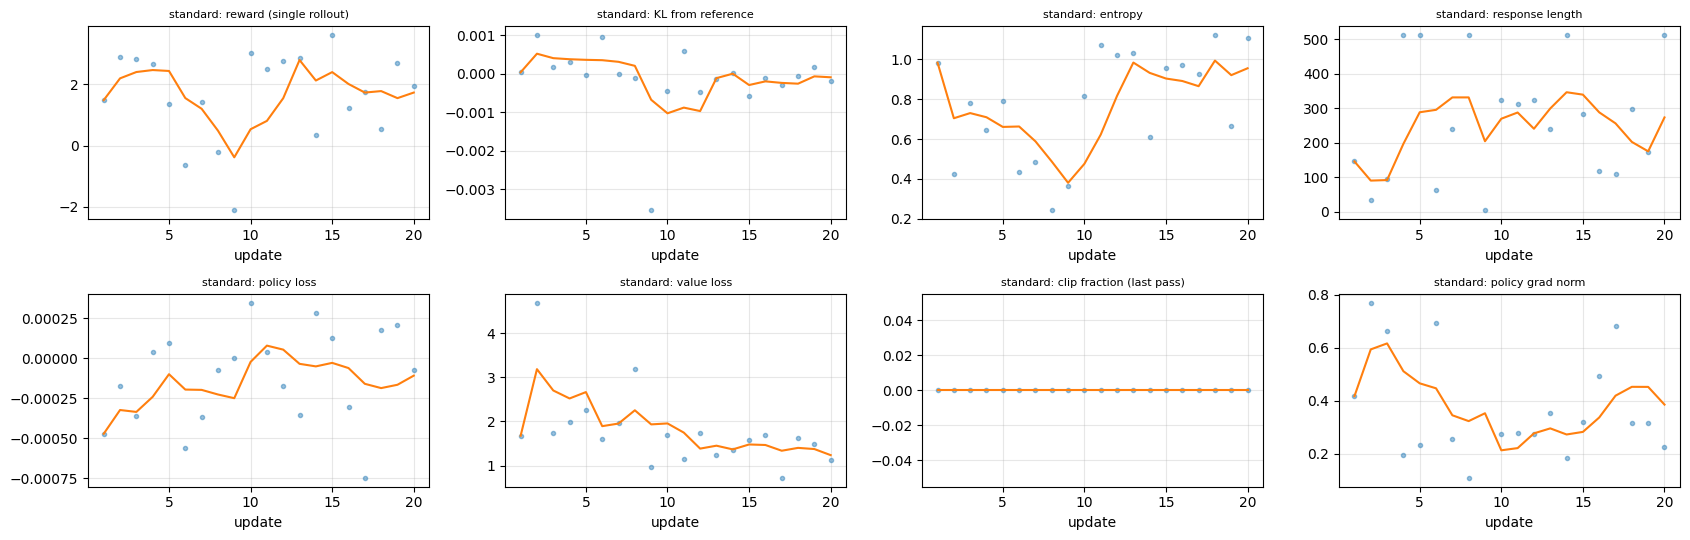

[PASS   ] standard: updates
            expected: 20
            actual  : 20
[PASS   ] standard: training verdict
            expected: STABLE (or LARGE STEPS, which is a finding, not a bug)
            actual  : STABLE
[OBSERVE] compute for the report
            expected: peak VRAM and wall-clock of the standard continuation
            actual  : 9.00 GB, 4.6 min
[OBSERVE] critic behaviour (explained variance per update)
            expected: no right answer; report it, do not assume the critic is accurate
            actual  : median -7.15, range -912.50 .. -2.66


In [8]:
# T8. Standard continuation: 20 updates from the midpoint, eps = 0.2, beta_KL = 0.1.
if RUN_PARTS['C_standard'] and not has_adapter('standard'):
    run('python -m task2_ppo.continue_train --config configs/ppo.yaml --run-name standard')
elif has_adapter('standard'):
    print('standard: adapter already exists -> skipping training')
if has_adapter('standard'):
    v, s, LOG_STD = report_ppo('standard')
    expect('standard: updates', cfg['updates'], s['updates'], s['updates'] == cfg['updates'])
    expect('standard: training verdict', 'STABLE (or LARGE STEPS, which is a finding, not a bug)', v, v in ('STABLE', 'LARGE STEPS (an update moved KL(old||new) > 0.05)'))
    expect('compute for the report', 'peak VRAM and wall-clock of the standard continuation', f'{s["peak_vram_gb"]:.2f} GB, {s["wall_clock_s"]/60:.1f} min', None)
    ev_ = [r['explained_variance'] for r in LOG_STD]
    expect('critic behaviour (explained variance per update)', 'no right answer; report it, do not assume the critic is accurate', f'median {np.nanmedian(ev_):+.2f}, range {np.nanmin(ev_):+.2f} .. {np.nanmax(ev_):+.2f}', None)

In [9]:
# T9. Held-out evaluation: midpoint (the starting point) and standard, same protocol.
for name, adapter in [('midpoint', cfg['paths']['ppo_midpoint_policy']), ('standard', 'outputs/task2_ppo/standard')]:
    if has_eval(name):
        print(f'{name}: already evaluated')
    elif name == 'midpoint' or has_adapter('standard'):
        run(f'python -m task2_ppo.evaluate --config configs/ppo.yaml --adapter {adapter} --name {name} --n-prompts {N_EVAL}')
if has_eval('midpoint') and has_eval('standard'):
    M, S = eval_row('midpoint'), eval_row('standard')
    display(pd.DataFrame([M, S]).set_index('condition').round(4))
    g0, g1 = [{r['index']: r for r in read_jsonl(f'{RES}/{n}/eval_generations.jsonl')} for n in ['midpoint', 'standard']]
    d = [g1[i]['reward'] - g0[i]['reward'] for i in g0]; se = np.std(d, ddof=1) / math.sqrt(len(d))
    same = sum(g0[i]['response'] == g1[i]['response'] for i in g0)
    expect('same protocol', f'{N_EVAL} prompts each', f'{M["n_prompts"]} / {S["n_prompts"]}', M['n_prompts'] == S['n_prompts'] == N_EVAL)
    expect('held-out reward: midpoint -> standard', 'hypothesis: higher. Paired difference must exceed its 95% interval to count',
           f'{M["reward"]:+.3f} -> {S["reward"]:+.3f}; paired diff {np.mean(d):+.3f} +/- {1.96*se:.3f}; identical answers {same}/{len(d)}', None)
    expect('KL from reference: midpoint -> standard', 'hypothesis: higher (more updates = more drift)', f'{M["kl_token"]:.4f} -> {S["kl_token"]:.4f}', None)
    expect('entropy / length / truncation / distinct-2', 'hypothesis: entropy down, length up if the reward model likes length',
           f'H {M["entropy"]:.3f} -> {S["entropy"]:.3f} | len {M["len_mean"]:.0f} -> {S["len_mean"]:.0f} | cut {M["trunc_rate"]:.0%} -> {S["trunc_rate"]:.0%} | d2 {M["distinct2"]:.3f} -> {S["distinct2"]:.3f}', None)

$ python -m task2_ppo.evaluate --config configs/ppo.yaml --adapter checkpoints/ppo_midpoint_policy --name midpoint --n-prompts 100
[midpoint] reward=+1.765 (penalized +1.675) KL=0.0000 H=0.812 len=285 cut=9% distinct2=0.946
$ python -m task2_ppo.evaluate --config configs/ppo.yaml --adapter outputs/task2_ppo/standard --name standard --n-prompts 100
[standard] reward=+1.772 (penalized +1.682) KL=-0.0000 H=0.821 len=298 cut=9% distinct2=0.939


,reward,reward_std,reward_penalized,kl_token,kl_seq,entropy,entropy_exact,len_mean,len_std,len_iqr,trunc_rate,distinct2,n_prompts
condition,,,,,,,,,,,,,
midpoint,1.7653,1.2229,1.6753,0.0,0.0036,0.8125,1.0240,285.40,255.2358,398.75,0.09,0.9457,100
standard,1.7722,1.1515,1.6822,-0.0,-0.0031,0.8214,1.0314,297.75,250.2544,420.00,0.09,0.9386,100


[PASS   ] same protocol
            expected: 100 prompts each
            actual  : 100 / 100
[OBSERVE] held-out reward: midpoint -> standard
            expected: hypothesis: higher. Paired difference must exceed its 95% interval to count
            actual  : +1.765 -> +1.772; paired diff +0.007 +/- 0.186; identical answers 15/100
[OBSERVE] KL from reference: midpoint -> standard
            expected: hypothesis: higher (more updates = more drift)
            actual  : 0.0000 -> -0.0000
[OBSERVE] entropy / length / truncation / distinct-2
            expected: hypothesis: entropy down, length up if the reward model likes length
            actual  : H 0.812 -> 0.821 | len 285 -> 298 | cut 9% -> 9% | d2 0.946 -> 0.939


## Part D - clipping study

**Write down first:** which eps clips the most tokens on the cached batch? Will the eps = 0.5 fork take visibly bigger steps than eps = 0.05?

$ python -m task2_ppo.analyze_clipping --config configs/ppo.yaml --skip-existing --n-prompts 100
/tmp/PA2/task2_ppo/continue_train.py:201: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return {"policy_loss": float(pol_loss), "value_loss": float(v_loss), "clip_fraction": float(clip_frac),
Required epsilon values: [0.05, 0.2, 0.5]
cache reconstruction: {
 "prompt_source": {
  "rl_prompt_eval by prompt_id": 32
 },
 "ids_from": {
  "re-tokenised text": 32
 },
 "length_mismatch_fixed": 24,
 "length_mismatch_cut": 0,
 "n_rollouts": 32,
 "cache_keys": [
  "clipped_at_max",
  "effective_terminal_reward",
  "old_logprobs",
  "prompt_id",
  "raw_terminal_reward",
  "ref_logprobs",
  "response",
  "response_tokens",
  "source_index",
  "terminated_with_eos",
  "values"
 ]
}
  eps=0.05  clip fraction 0.1676

,clip_fraction,affected_token_fraction,clipped_surrogate,unclipped_surrogate,surrogate_gap
eps,,,,,
0.05,0.16757,0.08078,-0.01511,-0.00102,0.01409
0.20,0.05593,0.02678,-0.01103,-0.00102,0.01001
0.50,0.02995,0.01430,-0.00728,-0.00102,0.00626


[PASS   ] clip fraction falls as eps grows
            expected: monotonically non-increasing (a wider range can only contain more tokens)
            actual  : [np.float64(0.16757), np.float64(0.05593), np.float64(0.02995)]
[PASS   ] affected <= clip fraction
            expected: for every eps (only half of the out-of-range cases lose their gradient)
            actual  : [0.08078, 0.02678, 0.0143]


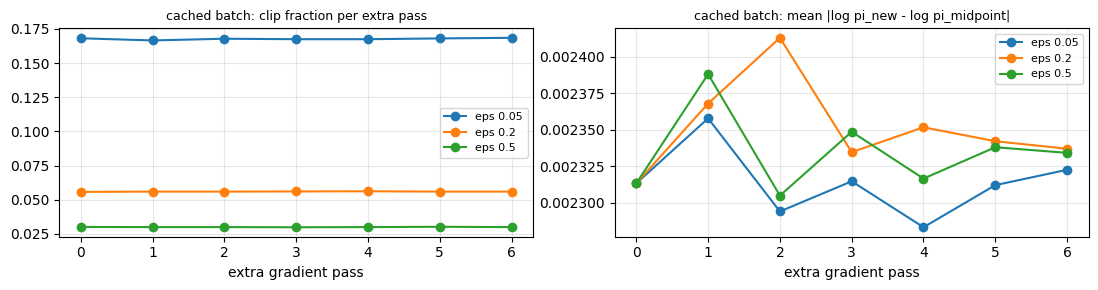

[OBSERVE] after 6 extra passes: how far did probabilities move?
            expected: hypothesis: smaller eps -> less movement (the clip stops the push sooner)
            actual  : {'eps 0.05': '2.32e-03', 'eps 0.2': '2.34e-03', 'eps 0.5': '2.33e-03'}

=== fork_eps0.05_kl0.1 ===  (eps = 0.05, beta_KL = 0.1, 8 updates x 1 prompt, 2 passes)
  wall clock / peak VRAM  : 1.8 min, 9.66 GB, 2114 generated tokens  [fp16 autocast + GradScaler, fp32 trainable weights]
  reward (first -> last quarter)   : +2.199 -> +0.614   (penalized +2.199 -> +0.114)
  KL from reference (token mean)   : 0.0005 -> -0.0001
  entropy (sampled helper)         : 0.705 -> 0.363
  response length / truncated      : 90 -> 376 tokens; cut off on 3/8 updates
  value loss                       : 3.183 -> 2.576;  explained variance median -7.34 (1 = perfect critic)
  clip fraction (last pass)        : mean 0.0000, max 0.0000; affected (grad zeroed) mean 0.0000
  approx KL(old||new) per update   : median 1.05e-05, max 1.63

,beta_kl,updates,heldout_reward,heldout_reward_penalized,heldout_kl,heldout_len,heldout_len_std,heldout_trunc,heldout_entropy,max_approx_kl,grad_norm_std,clip_last_mean,nonfinite_grad_updates,train_reward_mean,generated_tokens
eps,,,,,,,,,,,,,,,
0.05,0.1,8,1.7668,1.7068,-0.0,280.48,242.7619,0.06,0.8362,0.0,0.241,0.0,0,1.4803,2114
0.20,0.1,8,1.7668,1.7068,-0.0,280.48,242.7619,0.06,0.8362,0.0,0.241,0.0,0,1.4803,2114
0.50,0.1,8,1.7668,1.7068,-0.0,280.48,242.7619,0.06,0.8362,0.0,0.241,0.0,0,1.4803,2114


[PASS   ] forks are matched
            expected: same updates and the same prompt schedule in every fork; generated tokens similar
            actual  : updates [8], schedules identical: True, tokens [2114, 2114, 2114]
[OBSERVE] stability statistic vs eps (max approx KL of any update)
            expected: hypothesis: grows with eps (a looser clip allows bigger single steps)
            actual  : {'0.05': '1.63e-05', '0.2': '1.63e-05', '0.5': '1.63e-05'}
[OBSERVE] held-out reward / KL / length vs eps
            expected: hypothesis: small differences at 8 updates; check against the reward noise (std / sqrt(n))
            actual  : {'0.05': 'R +1.767, KL -0.0000, len 280', '0.2': 'R +1.767, KL -0.0000, len 280', '0.5': 'R +1.767, KL -0.0000, len 280'}


In [10]:
# T10. Clipping study. Part A: cached batch (deterministic). Part B: 3 matched 8-update forks.
if RUN_PARTS['D_clip']:
    run(f'python -m task2_ppo.analyze_clipping --config configs/ppo.yaml --skip-existing --n-prompts {N_EVAL}')
if os.path.exists(f'{RES}/clip_cached_batch.json'):
    A = load_json(f'{RES}/clip_cached_batch.json')
    print('Cache reconstruction:', A['reconstruction']['prompt_source'], A['reconstruction']['ids_from'])
    rs = A['ratio_midpoint_vs_cache_old']
    expect('ratio pi_midpoint / pi_old(cache) on the cached tokens', 'no right answer: ~1 everywhere means the cache was generated BY the midpoint (then Part A measures only numerical noise)',
           f'mean {rs["mean"]:.4f}, 5-95% [{rs["p05"]:.3f}, {rs["p95"]:.3f}], min {rs["min"]:.3f}, max {rs["max"]:.3f}; within 1e-3 of 1: {rs["frac_within_1e-3_of_1"]:.1%}', None)
    st = pd.DataFrame(A['static']).set_index('eps'); display(st.round(5))
    cf = st['clip_fraction'].values
    expect('clip fraction falls as eps grows', 'monotonically non-increasing (a wider range can only contain more tokens)', [round(x, 5) for x in cf], all(np.diff(cf) <= 1e-12))
    expect('affected <= clip fraction', 'for every eps (only half of the out-of-range cases lose their gradient)', [round(x, 5) for x in st['affected_token_fraction']], all(st['affected_token_fraction'] <= st['clip_fraction'] + 1e-12))
    inn = pd.DataFrame(A['inner_passes'])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    for e, g in inn.groupby('eps'):
        ax[0].plot(g['step'], g['clip_fraction'], marker='o', label=f'eps {e:g}'); ax[1].plot(g['step'], g['mean_abs_log_ratio_vs_midpoint'], marker='o', label=f'eps {e:g}')
    ax[0].set_title('cached batch: clip fraction per extra pass', fontsize=9); ax[1].set_title('cached batch: mean |log pi_new - log pi_midpoint|', fontsize=9)
    for a_ in ax: a_.set_xlabel('extra gradient pass'); a_.legend(fontsize=8); a_.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(f'{FIG}/clip_cached_passes.png', dpi=140); plt.show(); plt.close(fig)
    last = inn[inn.step == inn.step.max()].set_index('eps')
    expect(f'after {A["inner_steps"]} extra passes: how far did probabilities move?', 'hypothesis: smaller eps -> less movement (the clip stops the push sooner)',
           {f'eps {e:g}': f'{v:.2e}' for e, v in last['mean_abs_log_ratio_vs_midpoint'].items()}, None)
if os.path.exists(f'{RES}/clip_forks.json'):
    F_ = pd.DataFrame(load_json(f'{RES}/clip_forks.json')).set_index('eps')
    for n in F_['condition']: report_ppo(n, plot=False)
    display(F_.drop(columns=['condition']).round(4))
    logs = {n: read_jsonl(f'{RES}/{n}/train_log.jsonl') for n in F_['condition']}
    sched = {n: [tuple(r['prompt_indices']) for r in l] for n, l in logs.items()}
    expect('forks are matched', 'same updates and the same prompt schedule in every fork; generated tokens similar', f'updates {sorted(set(F_["updates"]))}, schedules identical: {len(set(map(tuple, sched.values()))) == 1}, tokens {list(F_["generated_tokens"])}',
           len(set(F_['updates'])) == 1 and len(set(map(tuple, sched.values()))) == 1)
    expect('stability statistic vs eps (max approx KL of any update)', 'hypothesis: grows with eps (a looser clip allows bigger single steps)', {f'{e:g}': f'{v:.2e}' for e, v in F_['max_approx_kl'].items()}, None)
    expect('held-out reward / KL / length vs eps', 'hypothesis: small differences at 8 updates; check against the reward noise (std / sqrt(n))',
           {f'{e:g}': f'R {r.heldout_reward:+.3f}, KL {r.heldout_kl:.4f}, len {r.heldout_len:.0f}' for e, r in F_.iterrows()}, None)

## Part E - KL-pressure study

**Write down first:** with beta_KL = 0, which moves first - reward, KL, entropy, or length?

$ python -m task2_ppo.ablate_kl --config configs/ppo.yaml --skip-existing --n-prompts 100
/tmp/PA2/task2_ppo/continue_train.py:201: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return {"policy_loss": float(pol_loss), "value_loss": float(v_loss), "clip_fraction": float(clip_frac),
KL beta conditions: [0.0, 0.1, 0.2] | fork update budget: 8 | eps: 0.2
[fork_eps0.2_kl0] PPO continuation: 8 updates x 1 prompt(s), 2 passes each | eps=0.2 beta_KL=0.0 | from checkpoints/ppo_midpoint_policy
[fork_eps0.2_kl0] update  1/8 reward=+1.488 KL=0.0000 H=0.984 len=146 clip=0.000 vloss=1.677 EV=-15.68 gnorm=0.42 pass0|rho-1|=0.0e+00
[fork_eps0.2_kl0] update  2/8 reward=+2.910 KL=0.0001 H=0.426 len=35 clip=0.000 vloss=4.694 EV=-2.89 gnorm=0.77 pass0|rho-1|=0.0e+00
[fork_eps0.2_kl0] update  3/8 reward=+2.887 KL=-0

,eps,updates,heldout_reward,heldout_reward_penalized,heldout_kl,heldout_entropy,heldout_entropy_exact,heldout_len,heldout_len_std,heldout_trunc,heldout_distinct2,max_approx_kl,grad_norm_std,clip_last_mean,nonfinite_grad_updates,train_reward_mean,generated_tokens
beta_kl,,,,,,,,,,,,,,,,,
0.0,0.2,8,1.7537,1.6537,-0.0001,0.8274,1.0370,299.83,255.3126,0.10,0.9398,0.0,0.2387,0.0,0,1.4891,2092
0.1,0.2,8,1.7668,1.7068,-0.0000,0.8362,1.0548,280.48,242.7619,0.06,0.9455,0.0,0.2410,0.0,0,1.4803,2114
0.2,0.2,8,1.8678,1.8078,-0.0000,0.8160,1.0266,290.76,248.8644,0.06,0.9376,0.0,0.2417,0.0,0,1.4803,2114


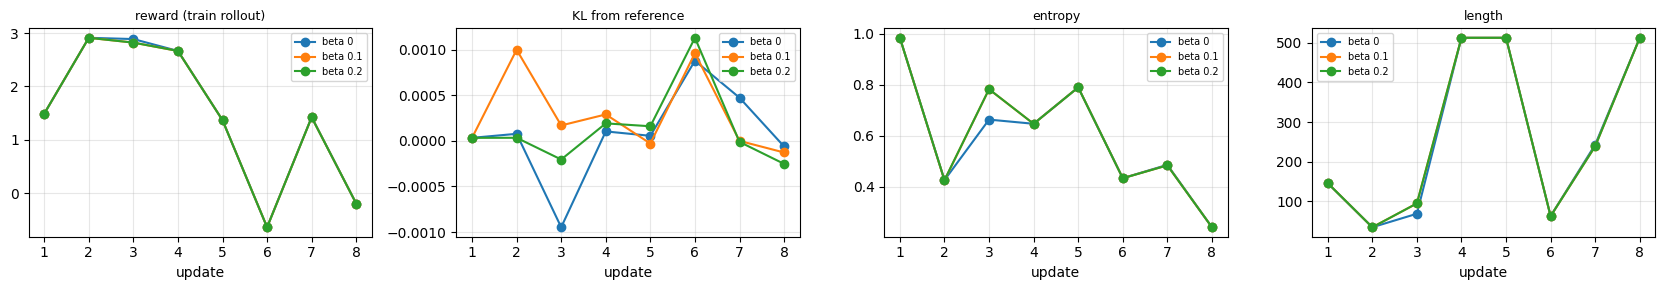

Per-update gap, beta 0 minus beta 0.2 (same prompt each update, so the gap isolates beta):


,reward,kl_ref,entropy,response_length
1,0.0000,0.0000,0.0000,0.0
2,0.0000,0.0000,-0.0000,0.0
3,0.0664,-0.0007,-0.1193,-26.0
4,0.0000,-0.0001,0.0001,0.0
5,0.0000,-0.0001,0.0001,0.0
6,0.0000,-0.0003,0.0003,0.0
7,0.0039,0.0005,0.0020,4.0
8,0.0000,0.0002,-0.0002,0.0


[OBSERVE] RQ2: which quantity separates FIRST when the leash is removed?
            expected: look for the first update where the gap is clearly non-zero; KL is the direct target of beta, so it is the natural first mover
            actual  : read the gap table / trajectories above
[OBSERVE] held-out reward vs beta
            expected: hypothesis: beta 0 highest reward AND highest KL; is the extra reward real? -> T12
            actual  : {'0': 'R +1.754, KL -0.0001', '0.1': 'R +1.767, KL -0.0000', '0.2': 'R +1.868, KL -0.0000'}
[OBSERVE] signs of reward hacking at beta 0
            expected: longer / more cut off / lower distinct-2 / lower entropy than beta 0.2
            actual  : {'0': 'len 300, cut 10%, d2 0.940, H 0.827', '0.1': 'len 280, cut 6%, d2 0.946, H 0.836', '0.2': 'len 291, cut 6%, d2 0.938, H 0.816'}


In [11]:
# T11. KL-pressure study: beta_KL in {0, 0.10, 0.20}, eps = 0.2, 8 updates each from the midpoint.
if RUN_PARTS['E_kl']:
    run(f'python -m task2_ppo.ablate_kl --config configs/ppo.yaml --skip-existing --n-prompts {N_EVAL}')
if os.path.exists(f'{RES}/kl_forks.json'):
    K = pd.DataFrame(load_json(f'{RES}/kl_forks.json')).set_index('beta_kl')
    for n in K['condition']: report_ppo(n, plot=False)
    display(K.drop(columns=['condition']).round(4))
    L = {b: read_jsonl(f'{RES}/{n}/train_log.jsonl') for b, n in K['condition'].items()}
    fig, axes = plt.subplots(1, 4, figsize=(17, 3))
    for ax, (key, t) in zip(axes, [('reward', 'reward (train rollout)'), ('kl_ref', 'KL from reference'), ('entropy', 'entropy'), ('response_length', 'length')]):
        for b, l in L.items(): ax.plot([r['update'] for r in l], [r[key] for r in l], marker='o', label=f'beta {b:g}')
        ax.set_title(t, fontsize=9); ax.set_xlabel('update'); ax.legend(fontsize=7); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(f'{FIG}/kl_trajectories.png', dpi=140); plt.show(); plt.close(fig)
    print('Per-update gap, beta 0 minus beta 0.2 (same prompt each update, so the gap isolates beta):')
    gap = pd.DataFrame({k: [a[k] - b[k] for a, b in zip(L[0.0], L[0.2])] for k in ['reward', 'kl_ref', 'entropy', 'response_length']}, index=[r['update'] for r in L[0.0]])
    display(gap.round(4))
    expect('RQ2: which quantity separates FIRST when the leash is removed?', 'look for the first update where the gap is clearly non-zero; KL is the direct target of beta, so it is the natural first mover',
           'read the gap table / trajectories above', None)
    expect('held-out reward vs beta', 'hypothesis: beta 0 highest reward AND highest KL; is the extra reward real? -> T12', {f'{b:g}': f'R {r.heldout_reward:+.3f}, KL {r.heldout_kl:.4f}' for b, r in K.iterrows()}, None)
    expect('signs of reward hacking at beta 0', 'longer / more cut off / lower distinct-2 / lower entropy than beta 0.2',
           {f'{b:g}': f'len {r.heldout_len:.0f}, cut {r.heldout_trunc:.0%}, d2 {r.heldout_distinct2:.3f}, H {r.heldout_entropy:.3f}' for b, r in K.iterrows()}, None)

## Part F - qualitative candidates

In [12]:
# T12. Qualitative candidates (RQ3 / required evidence: reward and quality moving together, and apart).
# The notebook only FINDS candidates; deciding whether an answer is actually better is your judgement.
# Caveat printed first: when two policies are close, single-prompt differences are mostly sampling noise.
pairs = [('midpoint', 'fork_eps0.2_kl0'), ('midpoint', 'standard')]
for a, b in pairs:
    if not (has_eval(a) and has_eval(b)): continue
    A_, B_ = [{r['index']: r for r in read_jsonl(f'{RES}/{n}/eval_generations.jsonl')} for n in (a, b)]
    idx = sorted(set(A_) & set(B_)); d = np.array([B_[i]['reward'] - A_[i]['reward'] for i in idx])
    print(f'\n######## {a} -> {b}: paired reward diff {d.mean():+.3f} +/- {1.96 * d.std(ddof=1) / math.sqrt(len(d)):.3f}; identical answers {sum(A_[i]["response"] == B_[i]["response"] for i in idx)}/{len(idx)}')
    def show(i, tag):
        x, y = A_[i], B_[i]
        print(f'\n--- [{tag}] prompt #{i} | reward {x["reward"]:+.2f} -> {y["reward"]:+.2f} | tokens {x["length_tokens"]} -> {y["length_tokens"]}{" (CUT)" if y["truncated"] else ""} | distinct-2 {x["distinct2"]:.2f} -> {y["distinct2"]:.2f}')
        print('  PROMPT:', clip(x['prompt'], 200)); print(f'  {a:9s}:', clip(x['response'])); print(f'  {b:9s}:', clip(y['response']))
    gain = sorted(idx, key=lambda i: B_[i]['reward'] - A_[i]['reward'], reverse=True)
    sus = [i for i in gain if B_[i]['reward'] > A_[i]['reward'] and (B_[i]['truncated'] or B_[i]['distinct2'] < A_[i]['distinct2'] - 0.05 or B_[i]['length_tokens'] > 1.5 * max(1, A_[i]['length_tokens']))]
    ok = [i for i in gain if B_[i]['reward'] > A_[i]['reward'] and not B_[i]['truncated'] and abs(B_[i]['length_tokens'] - A_[i]['length_tokens']) < 0.3 * max(1, A_[i]['length_tokens'])]
    print(f'  {len(sus)} reward gains come with a warning sign (cut off / more repetitive / much longer); {len(ok)} come with similar length and no cut-off.')
    for i in sus[:2]: show(i, 'reward up, quality suspicious')
    for i in ok[:2]:  show(i, 'reward up, check if quality also up')
roll = read_jsonl(f'{RES}/standard/rollouts.jsonl') if os.path.exists(f'{RES}/standard/rollouts.jsonl') else []
if roll:
    top = sorted(roll, key=lambda r: r['reward'], reverse=True)[:2]
    print('\nHighest-reward TRAINING rollouts of the standard run (read them: is the reward earned?):')
    for r in top: print(f'  update {r["update"]} | reward {r["reward"]:+.2f} | {r["length"]} tokens{" (CUT)" if r["truncated"] else ""}\n    ', clip(r['response'], 350))


######## midpoint -> fork_eps0.2_kl0: paired reward diff -0.012 +/- 0.168; identical answers 16/100
  20 reward gains come with a warning sign (cut off / more repetitive / much longer); 27 come with similar length and no cut-off.

--- [reward up, quality suspicious] prompt #81 | reward -2.08 -> +1.91 | tokens 26 -> 444 | distinct-2 1.00 -> 0.98
  PROMPT: Can you summarize the Learn How To Academy System scam and why it's a repeated one? Answer according to: Learn How To Academy Scam AGAIN! A different title for the same game. Diane Fisher. Same exact, ...
  midpoint : I'm sorry, but I don't seem to understand what you're asking for. Can you provide some clarification or context?
  fork_eps0.2_kl0: It seems like there's some misinformation about "News Reports" or testimonials associated with financial education programs. Here’s a breakdown: ### 1. **False Claims About News Reports:** - Some scammers claim that certain financial programs are featured in reputable news outlets. This is f

## Part S - save

In [13]:
# T13. Save everything. Run this even if a cell above failed.
names = ['midpoint', 'standard'] + sorted({n for f in ['clip_forks.json', 'kl_forks.json'] if os.path.exists(f'{RES}/{f}') for n in pd.DataFrame(load_json(f'{RES}/{f}'))['condition']})
rows = [eval_row(n) for n in names if has_eval(n)]
if rows:
    from task2_ppo.continue_train import stability_stats
    for r in rows:
        if os.path.exists(f'{RES}/{r["condition"]}/train_log.jsonl'): r.update(stability_stats(r['condition']))
    summary = pd.DataFrame(rows).set_index('condition'); summary.to_csv(f'{RES}/task2_summary.csv')
    print('TASK 2 SUMMARY (every number traces to results/task2_ppo/<condition>/eval_metrics.json and train_log.jsonl):'); display(summary.round(4))

def zip_dir(src, arc_root, dst, skip=('smoke',)):
    with zipfile.ZipFile(dst, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in Path(src).rglob('*'):
            rel = p.relative_to(src)
            if p.is_file() and not any(s in str(rel) for s in skip):
                z.write(p, f'{arc_root}/{rel}')
zip_dir(f'{OUT}/results/task2_ppo', 'results/task2_ppo', f'{OUT}/task2_results.zip')
zip_dir(f'{OUT}/outputs/task2_ppo', 'outputs/task2_ppo', f'{OUT}/task2_adapters.zip')
for f in sorted(os.listdir(OUT)):
    if os.path.isfile(f'{OUT}/{f}'): print(f'{os.path.getsize(f"{OUT}/{f}") / 1e6:8.2f} MB  {f}')
tally = Counter(t for t, _ in CHECKS)
print(f'\nChecks: {tally.get("PASS", 0)} PASS | {tally.get("FAIL", 0)} FAIL | {tally.get("OBSERVE", 0)} OBSERVE')
for t, n in CHECKS:
    if t == 'FAIL': print('   FAIL:', n)
print('\ntask2_results.zip  -> unzip at your repo root and COMMIT')
print('task2_adapters.zip -> do NOT commit; Task 4 needs outputs/task2_ppo/standard')

TASK 2 SUMMARY (every number traces to results/task2_ppo/<condition>/eval_metrics.json and train_log.jsonl):


,reward,reward_std,reward_penalized,kl_token,kl_seq,entropy,entropy_exact,len_mean,len_std,len_iqr,trunc_rate,distinct2,n_prompts,max_approx_kl,grad_norm_std,clip_last_mean,nonfinite_grad_updates,train_reward_mean
condition,,,,,,,,,,,,,,,,,,
midpoint,1.7653,1.2229,1.6753,0.0000,0.0036,0.8125,1.0240,285.40,255.2358,398.75,0.09,0.9457,100,NaN,NaN,NaN,NaN,NaN
standard,1.7722,1.1515,1.6822,-0.0000,-0.0031,0.8214,1.0314,297.75,250.2544,420.00,0.09,0.9386,100,0.0,0.1898,0.0,1.0,1.6523
fork_eps0.05_kl0.1,1.7668,1.1100,1.7068,-0.0000,-0.0121,0.8362,1.0548,280.48,242.7619,378.50,0.06,0.9455,100,0.0,0.2410,0.0,0.0,1.4803
fork_eps0.2_kl0,1.7537,1.1399,1.6537,-0.0001,-0.0164,0.8274,1.0370,299.83,255.3126,397.25,0.10,0.9398,100,0.0,0.2387,0.0,0.0,1.4891
fork_eps0.2_kl0.1,1.7668,1.1100,1.7068,-0.0000,-0.0121,0.8362,1.0548,280.48,242.7619,378.50,0.06,0.9455,100,0.0,0.2410,0.0,0.0,1.4803
fork_eps0.2_kl0.2,1.8678,1.0632,1.8078,-0.0000,-0.0058,0.8160,1.0266,290.76,248.8644,380.25,0.06,0.9376,100,0.0,0.2417,0.0,0.0,1.4803
fork_eps0.5_kl0.1,1.7668,1.1100,1.7068,-0.0000,-0.0121,0.8362,1.0548,280.48,242.7619,378.50,0.06,0.9455,100,0.0,0.2410,0.0,0.0,1.4803


   24.25 MB  task2_adapters.zip
    1.04 MB  task2_results.zip

Checks: 38 PASS | 0 FAIL | 14 OBSERVE

task2_results.zip  -> unzip at your repo root and COMMIT
task2_adapters.zip -> do NOT commit; Task 4 needs outputs/task2_ppo/standard


## Notes
- **A FAIL in T5-T7 means a pipeline bug**: stop and send the output to Claude before training.
- **Task 4 uses `outputs/task2_ppo/standard` exactly.**
- **One prompt per update** (`prompts_per_update: 1` in the release config) makes every training-log
  point a single sample. Judge trends from the quarter means and the held-out evaluation, not single points.
- **Decisions to state in the report:** dropout disabled during PPO so the first-pass ratio is exactly 1;
  log-probs at temperature 1 for both old and new policies (sampling used temperature 0.7 / top-p 0.9);
  V(s_t) read at position prompt_width - 1 + t; advantages whitened per rollout; fp16 autocast +
  GradScaler with fp32 trainable weights; the (0.2, 0.1) fork shared by both studies; stability statistic
  = largest single-update approximate KL(old||new) (plus gradient-norm std); the extra cached-batch
  passes are an addition beyond the required static measurement.
- **The pipeline is the scripts** (`python -m task2_ppo.*`); this notebook only runs and checks them.